In [1]:
import os
import numpy as np
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA, KernelPCA
from collections import Counter
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.spatial.distance import pdist, squareform

In [2]:
# GLOBAL PARAMETERS

IMG_SIZE     = 64
N_COMPONENTS = 150
RANDOM_STATE = 42
TEST_RATIO   = 0.10

DATASET_DIR = "bloodcells_dataset"

In [20]:
# READING FROM FOLDERS

def load_images(folder):
    X, y, label_map = [], [], {}
    uploaded = 0

    classi = sorted([c for c in os.listdir(folder)
                     if os.path.isdir(os.path.join(folder, c))])

    for idx, classe in enumerate(classi):
        label_map[classe] = idx
        class_folder = os.path.join(folder, classe)

        for filename in os.listdir(class_folder):
            if not filename.lower().endswith(('.jpg', '.png', '.jpeg')):
                continue

            path = os.path.join(class_folder, filename)
            img  = Image.open(path).convert('L')
            img  = img.resize((IMG_SIZE, IMG_SIZE))

            vettore = np.array(img).flatten() / 255.0
            X.append(vettore)
            y.append(idx)
            uploaded += 1

    print(f"Total images loaded: {uploaded}")
    return np.array(X), np.array(y), label_map

In [21]:
# INFO AND UPLOAD

X_all, y_all, label_map = load_images(DATASET_DIR)

print(f"\nNumber of images: {X_all.shape[0]}")
print(f"Feature dimension: {X_all.shape[1]}")
print(f"\nClasses: {label_map}")

inverse_map  = {v: k for k, v in label_map.items()}
distribution = {inverse_map[k]: v for k, v in Counter(y_all).items()}
print(f"Elements per class: {distribution}")

Total images loaded: 17092

Number of images: 17092
Feature dimension: 4096

Classes: {'basophil': 0, 'eosinophil': 1, 'erythroblast': 2, 'ig': 3, 'lymphocyte': 4, 'monocyte': 5, 'neutrophil': 6, 'platelet': 7}
Elements per class: {'basophil': 1218, 'eosinophil': 3117, 'erythroblast': 1551, 'ig': 2895, 'lymphocyte': 1214, 'monocyte': 1420, 'neutrophil': 3329, 'platelet': 2348}


In [5]:
# TRAIN / TEST SPLIT 

X_train, X_test, y_train, y_test = train_test_split(
    X_all, y_all,
    test_size=TEST_RATIO,
    stratify=y_all,
    random_state=RANDOM_STATE
)

print(f"Train: {X_train.shape[0]} ({(1-TEST_RATIO)*100:.0f}%)")
print(f"Test:  {X_test.shape[0]}  ({TEST_RATIO*100:.0f}%)")

Train: 15382 (90%)
Test:  1710  (10%)


In [6]:
# PIXEL CORRELATION (on raw data, before PCA)

subset_pixels = X_all[:, 0:100]
corr_matrix   = np.corrcoef(subset_pixels.T)
avg_corr      = np.mean(np.abs(corr_matrix[np.triu_indices(100, k=1)]))
print(f"Average pixel correlation (raw): {avg_corr:.3f}")

Average pixel correlation (raw): 0.157


In [7]:
# CLASS CENTROIDS IN RAW PIXEL SPACE

n_classes = len(np.unique(y_all))
centroids  = np.array([X_all[y_all == i].mean(axis=0) for i in range(n_classes)])
dist_matrix = squareform(pdist(centroids))
mean_dist   = np.mean(dist_matrix[np.triu_indices(n_classes, k=1)])
print(f"Avg inter-class distance (raw pixel space): {mean_dist:.2f}")

Avg inter-class distance (raw pixel space): 4.20


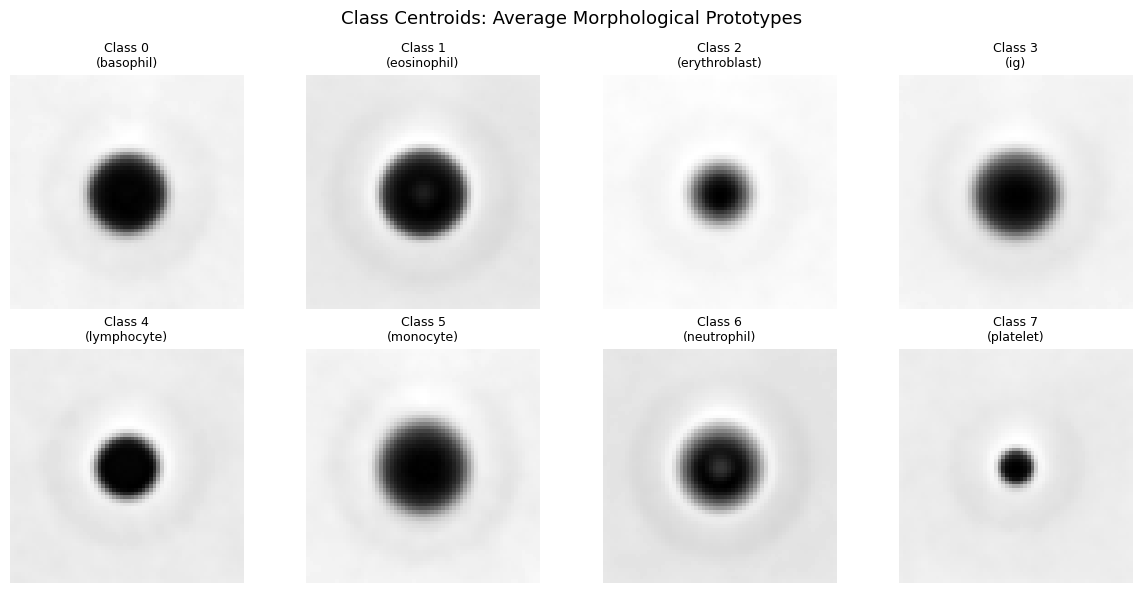

In [8]:
# CLASS CENTROIDS VISUALIZATION

fig, axes = plt.subplots(2, 4, figsize=(12, 6))
fig.suptitle('Class Centroids: Average Morphological Prototypes', fontsize=13)

class_names = [inverse_map[i] for i in range(n_classes)]
for i, ax in enumerate(axes.flat):
    centroid_img = centroids[i].reshape(IMG_SIZE, IMG_SIZE)
    ax.imshow(centroid_img, cmap='gray')
    ax.set_title(f'Class {i}\n({class_names[i]})', fontsize=9)
    ax.axis('off')

plt.tight_layout()
plt.show()

In [19]:
# STANDARDIZATION (fit only on X_train, transform both)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)

In [18]:
# PCA (fit only on X_train_scaled)

pca = PCA(n_components=N_COMPONENTS, random_state=RANDOM_STATE)
pca.fit(X_train_scaled)

X_train_pca = pca.transform(X_train_scaled)
X_test_pca  = pca.transform(X_test_scaled)

variance = np.sum(pca.explained_variance_ratio_) * 100
print(f"PCA components: {N_COMPONENTS}")
print(f"Explained variance: {variance:.2f}%")

# with 50  components: ~55%
# with 100 components: ~68%
# with 150 components: 74.12%  
# with 200 components: ~81%

PCA components: 150
Explained variance: 74.12%


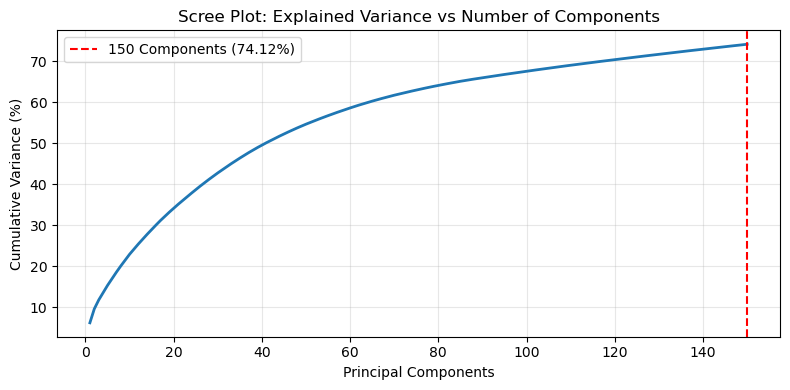

In [11]:
# SCREE PLOT

cumvar = np.cumsum(pca.explained_variance_ratio_) * 100

plt.figure(figsize=(8, 4))
plt.plot(range(1, N_COMPONENTS + 1), cumvar, linewidth=2)
plt.axvline(x=N_COMPONENTS, color='red', linestyle='--',
            label=f'{N_COMPONENTS} Components ({variance:.2f}%)')
plt.xlabel('Principal Components')
plt.ylabel('Cumulative Variance (%)')
plt.title('Scree Plot: Explained Variance vs Number of Components')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [12]:
# CORRELATION AND INTER-CLASS DISTANCE AFTER PCA

corr_matrix_pca = np.corrcoef(X_train_pca.T)
upper_tri_pca   = corr_matrix_pca[np.triu_indices(N_COMPONENTS, k=1)]
avg_corr_pca    = np.mean(np.abs(upper_tri_pca))

new_centroids   = np.array([X_train_pca[y_train == i].mean(axis=0) for i in range(n_classes)])
new_dist_matrix = squareform(pdist(new_centroids))
new_mean_dist   = np.mean(new_dist_matrix[np.triu_indices(n_classes, k=1)])

print(f"Avg correlation after PCA:          {avg_corr_pca:.6f}")
print(f"Avg inter-class distance after PCA: {new_mean_dist:.2f}  (was {mean_dist:.2f} before)")

Avg correlation after PCA:          0.000042
Avg inter-class distance after PCA: 21.35  (was 4.20 before)


In [13]:
# KERNEL PCA COMPARISON (RBF)

kpca = KernelPCA(n_components=N_COMPONENTS, kernel='rbf', gamma=None, n_jobs=-1)
X_train_kpca = kpca.fit_transform(X_train_scaled)

k_centroids  = np.array([X_train_kpca[y_train == i].mean(axis=0) for i in range(n_classes)])
k_mean_dist  = np.mean(pdist(k_centroids))

print(f"Linear PCA inter-class distance: {new_mean_dist:.2f}")
print(f"Kernel PCA inter-class distance: {k_mean_dist:.2f}")
print(f"=> Linear PCA chosen for compatibility with linear classifier.")

Linear PCA inter-class distance: 21.35
Kernel PCA inter-class distance: 0.20
=> Linear PCA chosen for compatibility with linear classifier.


In [17]:
# FINAL OUTPUT 

A_train = X_train_pca   # (15382, 150)
b_train = y_train        # (15382,)
A_test  = X_test_pca    # (1710, 150)
b_test  = y_test         # (1710,)
k       = len(label_map) # 8

print(f"A_train: {A_train.shape} ")
print(f"b_train: {b_train.shape}")
print(f"A_test:  {A_test.shape} ")
print(f"b_test:  {b_test.shape}")
print(f"k (classes): {k}")

A_train: (15382, 150) 
b_train: (15382,)
A_test:  (1710, 150) 
b_test:  (1710,)
k (classes): 8


In [16]:
np.savez("blood_data.npz",
    A_train=A_train,
    b_train=b_train,
    A_test=A_test,
    b_test=b_test
)

print ("Executed")

Executed
